# 3. The squad, and who it played

Notebook 02 established the shift: about **+0.7** goals of expected goal
difference between 2015 and 2026, carried by attack rather than defence, matched
by no regional peer, and turning no later than early 2022.

Two things decide a national team's results, and both are visible in this data
before any goal is scored: **who gets picked**, and **who they get to play**.
This notebook takes them in that order, because the second is the thing most
easily mistaken for the first.

**Part 1 — the squad.** Four questions:

1. What formation did Jordan play, and when did that move?
2. Did the *shape* settle, or only the personnel?
3. How concentrated did the playing time become?
4. Where do these players earn their club football, and did that move?

**Part 2 — the opposition.** Three more:

5. When did the opponents get harder, and was it gradual or sudden?
6. Was that **chosen or earned**? Friendlies are arranged; qualifiers are not.
7. How does the opposition set up against Jordan, and did that change?

Window **2015+**, split **2022-07-01**, 98 matches before and 45 after. Every
difference carries a block-bootstrap interval clustered on six-month windows
(**Künsch 1989**): matches inside a window share opponents, a manager and a
squad, so they are not independent draws.

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

OUT = ROOT / "outputs"
SQUAD = OUT / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"]).sort_values("date")
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
ap = pd.read_csv(SQUAD / "appearances_combined.csv")
ja = ap[ap.squad_id == "3e22f0fa"].copy()
ja["Min"] = pd.to_numeric(ja.Min, errors="coerce")

mt = mt[mt.date >= START].copy()
goals = goals[goals.date >= START].copy()
for d in (mt, goals):
    d["era"] = np.where(d.date < CUT, "pre", "post")
# six-month blocks: matches inside a window share a squad, a manager and a set
# of opponents, so the block is the unit a bootstrap resamples (Kunsch 1989)
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)

# A scorer is a player id, never a name -- the same man is transliterated
# several ways across sources (notebook 01, section 6).
gj = goals.dropna(subset=["scorer_player_id"]).copy()
NAMES = ja.dropna(subset=["player_id"]).groupby("player_id").Player.agg(
    lambda s: s.mode().iloc[0])
BLOCKS = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}


def block_boot(fn, nb=2000, frame=None):
    """Resample six-month blocks within each era; return (observed, lo, hi)."""
    src = mt if frame is None else frame
    blocks = {e: [d for _, d in src[src.era == e].groupby("blk")]
              for e in ("pre", "post")}
    obs = fn(src[src.era == "post"]) - fn(src[src.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([blocks[e][i] for i in
                           rng.integers(0, len(blocks[e]), len(blocks[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    return (obs, *np.percentile(vals, [2.5, 97.5]))

## Part 1 — the squad

### 1.1 The shape

Formation arrives two ways and they can be checked against each other: FBref's
**reported** label, and a shape **derived** from the positions of the eleven who
started. Where both exist they agree on the size of the back line in every single
match, which is what makes the measure safe to use across eras — unlike the
position labels themselves (notebook 01, section 5).

In [2]:
mt["backline"] = pd.to_numeric(
    mt.formation_best.astype(str).str.split("-").str[0], errors="coerce")
# named "line", not "shape": mt.shape is the DataFrame's own attribute
mt["line"] = np.where(mt.backline.isin([3, 5]), "back 3 or 5",
                      np.where(mt.backline == 4, "back 4", None))
both = mt.dropna(subset=["formation", "xi_shape"])
AGREE = (both.formation.str.split("-").str[0]
         == both.xi_shape.str.split("-").str[0]).mean()
FORM_N = (len(both), int(mt.line.notna().sum()), len(mt))

**Plotted, left:** every match since 2015, stacked by the size of the back line
Jordan played. **Right:** the same thing collapsed to one number per era — the
share of matches played with a back three or five.

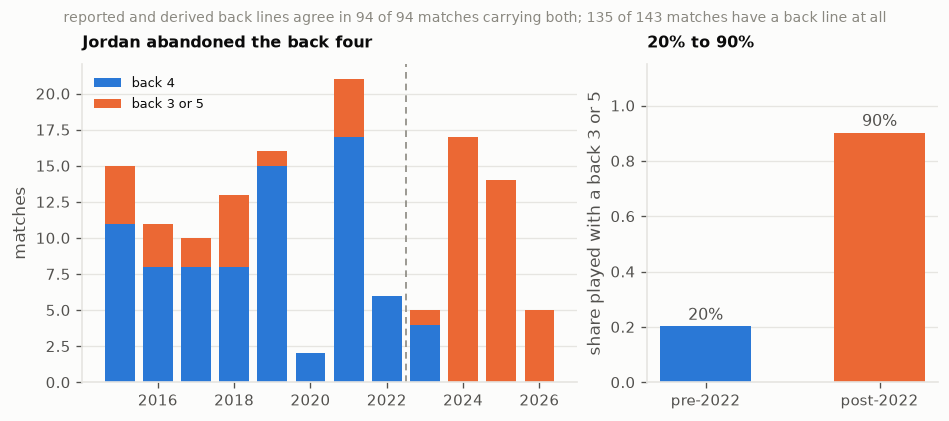

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.4),
                         gridspec_kw={"width_ratios": [1.7, 1]})
a = axes[0]
d = mt.dropna(subset=["line"])
t = pd.crosstab(d.date.dt.year, d.line)
for c in ("back 4", "back 3 or 5"):
    if c not in t:
        t[c] = 0
t = t[["back 4", "back 3 or 5"]]
a.bar(t.index, t["back 4"], color=viz.BLUE, label="back 4", width=0.78)
a.bar(t.index, t["back 3 or 5"], bottom=t["back 4"], color=viz.ORANGE,
      label="back 3 or 5", width=0.78)
a.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
a.set_ylabel("matches")
a.set_title("Jordan abandoned the back four", fontsize=9.5)
a.legend(fontsize=8, loc="upper left")
viz.despine(a)

b = axes[1]
sh = (d.assign(b3=d.line.eq("back 3 or 5"))
      .groupby("era").b3.mean().reindex(["pre", "post"]))
b.bar([0, 1], sh.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(sh.values):
    b.annotate(f"{v:.0%}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9.5, color=viz.INK_2)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(0, 1.15)
b.set_ylabel("share played with a back 3 or 5")
b.set_title("20% to 90%", fontsize=9.5)
viz.despine(b)
fig.suptitle(f"reported and derived back lines agree in "
             f"{int(AGREE * FORM_N[0])} of {FORM_N[0]} matches carrying both; "
             f"{FORM_N[1]} of {FORM_N[2]} matches have a back line at all",
             fontsize=8.5, color=viz.INK_MUTED)
plt.show()

**Plotted, left:** the era difference in back-three share with its
block-bootstrap interval. **Right:** how many *distinct* formations Jordan used
each year — the label under each bar reads "distinct shapes / matches that year",
so a tall bar on few matches is a team with no settled shape.

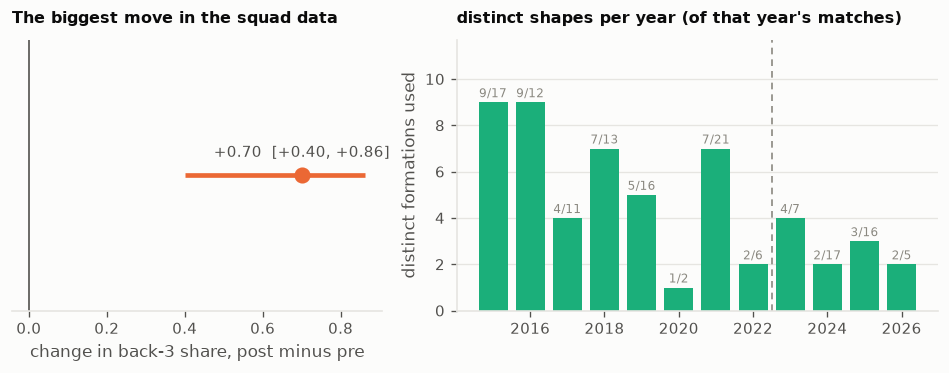

In [4]:
# A match with no recorded formation is NOT evidence of a back four, so the
# unknowns leave the denominator rather than counting against it. Eight matches,
# four in each era; including them understates the change by 0.07.
def b3(frame):
    v = frame.line.dropna()
    return v.eq("back 3 or 5").mean() if len(v) else np.nan


BACK3 = block_boot(b3, nb=3000)

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1, 1.3]})
a = axes[0]
a.hlines(0, BACK3[1], BACK3[2], color=viz.ORANGE, lw=2.8)
a.scatter([BACK3[0]], [0], color=viz.ORANGE, s=75, zorder=3)
a.axvline(0, color=viz.INK_2, lw=1.0)
a.annotate(f"{BACK3[0]:+.2f}  [{BACK3[1]:+.2f}, {BACK3[2]:+.2f}]",
           (BACK3[0], 0), xytext=(0, 11), ha="center",
           textcoords="offset points", fontsize=9, color=viz.INK_2)
a.set_ylim(-1, 1)
a.set_yticks([])
a.set_xlabel("change in back-3 share, post minus pre")
a.set_title("The biggest move in the squad data", fontsize=9.5)
viz.despine(a, keep=("bottom",))

b = axes[1]
nf = mt.dropna(subset=["formation_best"]).groupby(
    mt.date.dt.year).formation_best.nunique()
nm = mt.groupby(mt.date.dt.year).size()
b.bar(nf.index, nf.values, color=viz.AQUA, width=0.78)
for x_, v, m_ in zip(nf.index, nf.values, nm.reindex(nf.index).values):
    b.annotate(f"{v}/{m_}", (x_, v), xytext=(0, 3), ha="center",
               textcoords="offset points", fontsize=7, color=viz.INK_MUTED)
b.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
b.set_ylabel("distinct formations used")
b.set_ylim(0, nf.max() * 1.3)
b.set_title("distinct shapes per year (of that year's matches)", fontsize=9.5)
viz.despine(b)
plt.show()

**Jordan stopped being a back-four team.** A back three or five appears in
**20%** of pre-2022 matches and **90%** after — a change of **+0.70, 95% [+0.40,
+0.86]**, and the largest single move anywhere in the squad data.

**This is not a labelling artefact**, which matters because the neighbouring
measure was. FBref's reported formation and the shape derived independently from
the XI's own positions agree on the back line in **every match where both
exist**, and each source alone gives the same story (0.10 → 0.89 reported, 0.20 →
0.90 derived).

🚨 It does **not** put more midfielders on the pitch, whatever the team sheets
say. By each player's usual position the post-2022 XI carries *fewer* midfielders
(0.27 → 0.23 of the outfield) and more defenders (4.29 → 4.59), which is what a
back three is. The per-match labels say the opposite only because full-backs
became wing-backs and were written down as LM and RM.

### 1.2 Who actually played

Every measure in this notebook reduces to one fact — who started which match — so
it is worth drawing that fact directly before summarising it.

**Plotted:** one row per player, ordered by the date of their first start. A dot
is a start; the line joins first to last. A rebuild therefore reads as a
staircase of new rows, and a settled side as long unbroken runs across the
middle. The ten most-used players are named on the right. Shaded band 2021,
dashed line the cut.

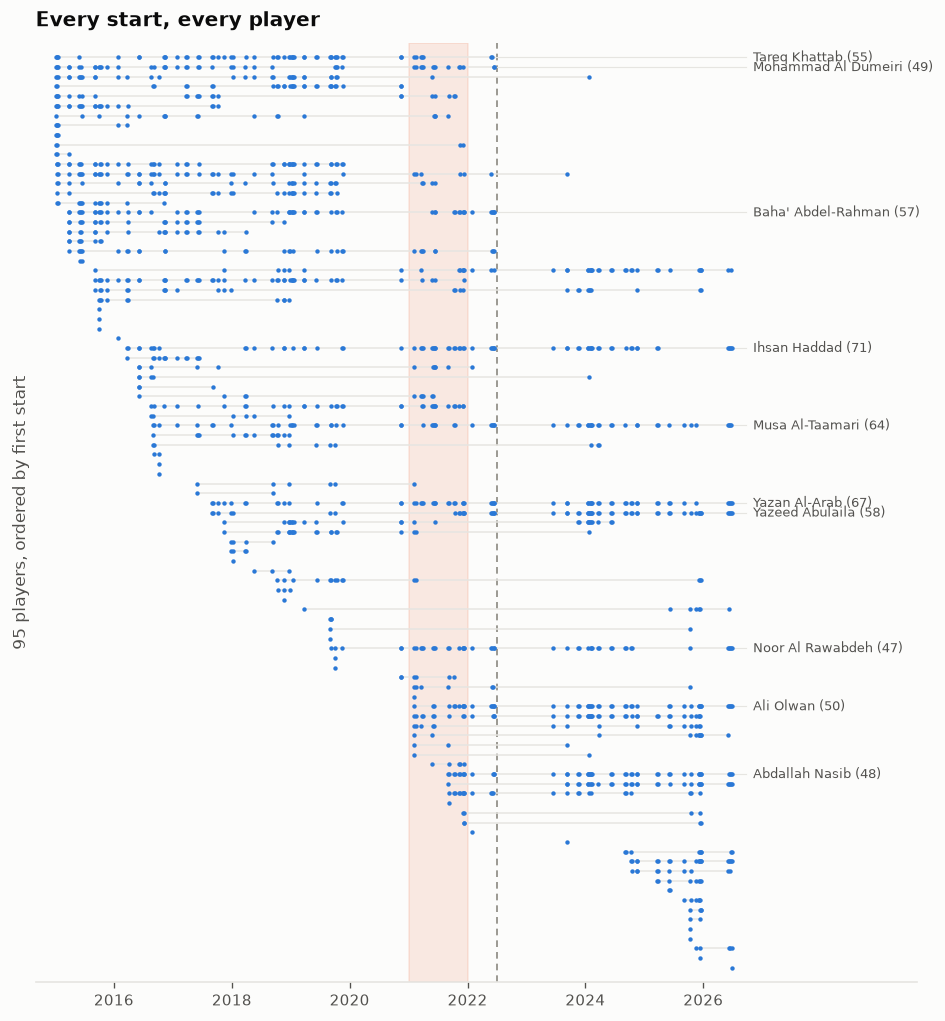

In [5]:
REBUILD = (pd.Timestamp("2021-01-01"), pd.Timestamp("2022-01-01"))
xi = mt.dropna(subset=["starting_xi"]).copy()
xi["ids"] = xi.starting_xi.map(
    lambda s: [p["id"] for p in json.loads(s) if p.get("id")])
starts = {}
for r in xi.sort_values("date").itertuples():
    for pid in r.ids:
        starts.setdefault(pid, []).append(r.date)
order = sorted(starts, key=lambda p: (starts[p][0], -len(starts[p])))

fig, ax = plt.subplots(figsize=(7.8, 8.4))
ax.axvspan(*REBUILD, color=viz.ORANGE, alpha=0.13, zorder=0)
ax.axvline(CUT, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=1)
for i, pid in enumerate(order):
    d = starts[pid]
    ax.plot([d[0], d[-1]], [i, i], color=viz.GRID, lw=0.9, zorder=2)
    ax.scatter(d, np.full(len(d), i), s=7, color=viz.BLUE, zorder=3,
               linewidths=0)
# labels in an aligned column on the right, not floating at each career end
LBL = xi.date.max() + pd.Timedelta(days=90)
for pid in sorted(starts, key=lambda p: -len(starts[p]))[:10]:
    i = order.index(pid)
    ax.plot([starts[pid][-1], LBL], [i, i], color=viz.GRID, lw=0.7, zorder=1)
    ax.annotate(f"{NAMES.get(pid, pid)} ({len(starts[pid])})", xy=(LBL, i),
                xytext=(4, 0), va="center", textcoords="offset points",
                fontsize=7.5, color=viz.INK_2)
ax.set_ylim(-1.5, len(order) + 0.5)
ax.invert_yaxis()
ax.set_yticks([])
ax.set_ylabel(f"{len(order)} players, ordered by first start")
ax.set_xlim(START - pd.Timedelta(days=120),
            xi.date.max() + pd.Timedelta(days=1150))
# ticks stop where the data does, so the right-hand strip reads as a label
# column rather than as two more years of empty fixtures
YRS = list(range(2016, 2027, 2))
ax.set_xticks(pd.to_datetime([f"{y}-01-01" for y in YRS]))
ax.set_xticklabels([str(y) for y in YRS])
ax.set_title("Every start, every player")
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
plt.show()

Read top to bottom: a staircase of new rows through 2021, long unbroken runs
across the middle as the same names start match after match, and a second
staircase from 2025. That is the raw material every measure below is built from.

### 1.3 How settled, measured two ways

Two measures, on the same 0–1 scale, both meaning "the identical eleven every
match" at 1.0:

- **minutes to the top eleven** — the share of all Jordan playing time taken by
  the eleven most-used players. Concentration of who plays.
- **pairs who had started together** — for each match, the share of the previous
  24 months that the average *pair* in the XI had already started together. This
  is team familiarity as defined in the *Journal of Big Data* (2025) shared-
  experience paper, divided by the matches available in the window: raw pairwise
  counts accumulate with time, so an unadjusted version rises for reasons that
  have nothing to do with Jordan.

That paper's own conclusion is a caution worth carrying: at match level, shared
experience did **not** predict results once team strength was controlled for. And
van Vugt et al. find an inverted-U between stability and performance. So "more
settled" is measured here, not assumed to be better.

In [6]:
# Both rates depend on the match and the FULL history behind it, never on which
# matches a bootstrap draw happens to pick -- so they are computed once per
# match here, and resampling only averages them.
mins_by_match = {m: s.groupby("player_id").Min.sum() for m, s in ja.groupby("match_id")}
fam_rate = {}
for r in xi.itertuples():
    prior = xi[(xi.date >= r.date - pd.Timedelta(days=730)) & (xi.date < r.date)]
    if len(prior) < 15:                # too little history to form a rate
        continue
    pc = {}
    for q in prior.itertuples():
        for pair in combinations(sorted(q.ids), 2):
            pc[pair] = pc.get(pair, 0) + 1
    pairs = list(combinations(sorted(r.ids), 2))
    fam_rate[r.match_id] = np.mean([pc.get(p, 0) for p in pairs]) / len(prior)
XI_COVER = (len(fam_rate), len(xi))


def top11(d):
    tot = {}
    for m in d.match_id:
        s = mins_by_match.get(m)
        if s is None:
            continue
        for pid, v in s.items():
            tot[pid] = tot.get(pid, 0) + v
    if not tot:
        return np.nan
    p = pd.Series(tot).sort_values(ascending=False)
    return p.head(11).sum() / p.sum()


def windowed(d):
    v = [fam_rate[m] for m in d.match_id if m in fam_rate]
    return np.mean(v) if v else np.nan


MEASURES = [("minutes: top-11 share", top11),
            ("familiarity rate (pairs)", windowed)]
res = []
for lab, fn in MEASURES:
    o, lo, hi = block_boot(fn, nb=600)
    res.append({"measure": lab, "pre": fn(mt[mt.era == "pre"]),
                "post": fn(mt[mt.era == "post"]), "diff": o, "lo": lo, "hi": hi})
settled = pd.DataFrame(res)

**Plotted:** levels, not only the change. Each row is one measure; the blue dot
is its pre-2022 value, the orange its post-2022 value, and the text on the right
is the difference with its 95% interval. Both measures are shares on the same
scale, so one axis carries them.

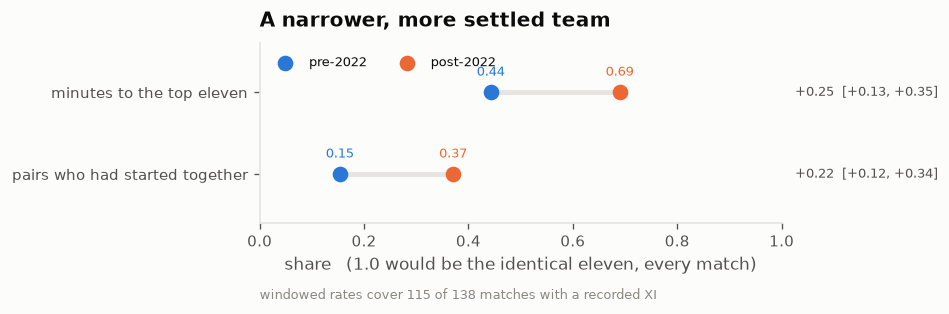

In [7]:
fig, ax = plt.subplots(figsize=(7.8, 2.4))
d = settled.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
ax.hlines(y, d.pre, d.post, color=viz.GRID, lw=3.0, zorder=1, capstyle="round")
ax.scatter(d.pre, y, color=viz.BLUE, s=70, zorder=3, label="pre-2022")
ax.scatter(d.post, y, color=viz.ORANGE, s=70, zorder=3, label="post-2022")
for i, r in d.iterrows():
    ax.annotate(f"{r.pre:.2f}", (r.pre, i), xytext=(0, 10), ha="center",
                textcoords="offset points", fontsize=8, color=viz.BLUE)
    ax.annotate(f"{r.post:.2f}", (r.post, i), xytext=(0, 10), ha="center",
                textcoords="offset points", fontsize=8, color=viz.ORANGE)
    ax.annotate(f"{r['diff']:+.2f}  [{r.lo:+.2f}, {r.hi:+.2f}]", (1.0, i),
                xytext=(8, 0), va="center", textcoords="offset points",
                fontsize=8, color=viz.INK_2)
ax.set_yticks(y)
# labels must follow the (reversed) frame, not a hardcoded list -- getting this
# wrong silently puts the minutes number on the familiarity row
NICE = {"minutes: top-11 share": "minutes to the top eleven",
        "familiarity rate (pairs)": "pairs who had started together"}
ax.set_yticklabels([NICE.get(m, m) for m in d.measure])
ax.set_xlim(0, 1.0)
ax.set_ylim(-0.6, len(d) - 0.4)
ax.set_xlabel("share   (1.0 would be the identical eleven, every match)")
ax.set_title("A narrower, more settled team")
ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.annotate(f"windowed rates cover {XI_COVER[0]} of {XI_COVER[1]} matches "
            f"with a recorded XI", xy=(0, -0.42), xycoords="axes fraction",
            fontsize=7.5, color=viz.INK_MUTED)
viz.despine(ax)
ax.grid(axis="y", visible=False)
plt.show()

**Plotted:** the same question from the other side. Jaccard distance between each
starting eleven and the one before it — 0 means an unchanged side, 1 means all
eleven changed. **Left:** the yearly mean, marker area being that year's matches.
**Right:** the two era means.

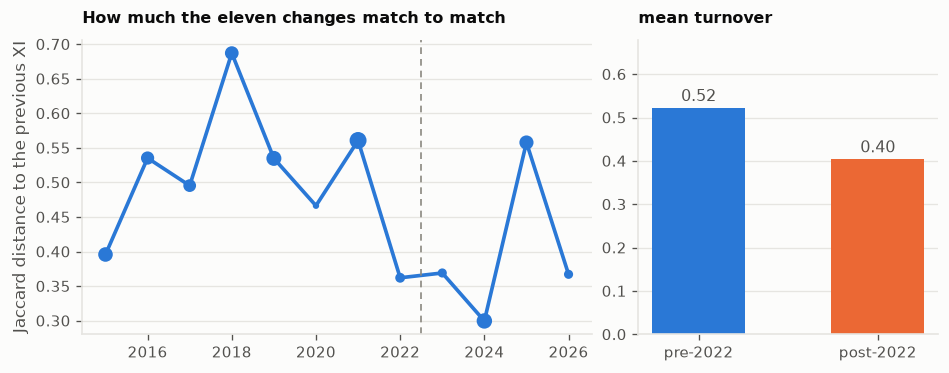

In [8]:
xs = xi.sort_values("date")
jac, jd, prev = [], [], None
for r in xs.itertuples():
    if prev is not None:
        a_, b_ = set(prev), set(r.ids)
        jac.append(1 - len(a_ & b_) / len(a_ | b_))
        jd.append(r.date)
    prev = r.ids
turn = pd.DataFrame({"date": jd, "turnover": jac})
turn["era"] = np.where(turn.date < CUT, "pre", "post")

fig, axes = plt.subplots(1, 2, figsize=(7.8, 3.0),
                         gridspec_kw={"width_ratios": [1.7, 1]})
a = axes[0]
yr = turn.groupby(turn.date.dt.year).turnover.agg(["mean", "size"])
a.plot(yr.index, yr["mean"], color=viz.BLUE, lw=2.2)
a.scatter(yr.index, yr["mean"], color=viz.BLUE, s=yr["size"] * 4, zorder=3)
a.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
a.set_ylabel("Jaccard distance to the previous XI")
a.set_title("How much the eleven changes match to match", fontsize=9.5)
viz.despine(a)

b = axes[1]
m_ = turn.groupby("era").turnover.mean().reindex(["pre", "post"])
b.bar([0, 1], m_.values, width=0.52, color=[viz.BLUE, viz.ORANGE])
for i, v in enumerate(m_.values):
    b.annotate(f"{v:.2f}", (i, v), xytext=(0, 4), ha="center",
               textcoords="offset points", fontsize=9.5, color=viz.INK_2)
b.set_xticks([0, 1])
b.set_xticklabels(["pre-2022", "post-2022"])
b.set_ylim(0, m_.max() * 1.3)
b.set_title("mean turnover", fontsize=9.5)
viz.despine(b)
plt.show()

**Both clear zero.** The top eleven take **44% to 69%** of all playing time, and
the average pair in the XI has started **0.15 to 0.37** of the previous two years
together.

Turnover says the same thing from the other side — the eleven that starts is
closer to the eleven that started last time. Note it does **not** fall to zero:
Jordan still changes players, it just changes fewer of them, inside a shape that
no longer changes at all.

🚨 **These two are one measure, not two.** Appearance rate at player level and
familiarity at pair level correlate at r = 0.99 and cannot come apart by
construction. They are shown together because they are differently *readable*,
not because they are independent evidence.

### 1.4 Where they play their club football

The squad narrowed and settled. A different question about the same men: **where
do they earn their living, and did that move?**

FBref cannot answer it — its reader covers nine leagues, none of them Jordanian,
Gulf or Asian. This comes from five Wikipedia tournament squad lists
(`wiki_squads.py`), each row carrying the club and the club's country at the
moment that squad was named.

**Plotted, left:** the share of player-eras whose club is in Jordan, elsewhere in
the Arab world or Asia, or in Europe. Bars are shares of each era — the label
gives the count and that era's total, because the eras hold different numbers of
players. **Right:** the change in share playing abroad, by line, with a bootstrap
interval; the axis label gives players per cell.

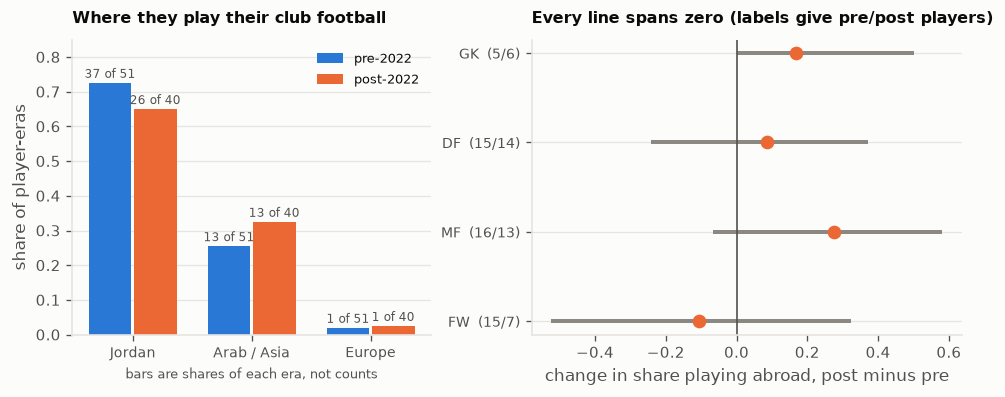

In [9]:
# Counted per PLAYER per era, not per squad place: a regular named in three
# squads would otherwise count three times, and that alone flips the forward
# result from 47%->29% to 56%->56%.
pe = pd.read_csv(SQUAD / "tournament_player_eras.csv")
pe["abroad"] = pe.region.ne("Jordan")
REG = ["Jordan", "Arab / Asia", "Europe"]

fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.2),
                         gridspec_kw={"width_ratios": [1, 1.2]})
a = axes[0]
rs = (pd.crosstab(pe.region, pe.era, normalize="columns")
      .reindex(columns=["pre", "post"]).reindex(REG).fillna(0))
rn = (pd.crosstab(pe.region, pe.era).reindex(columns=["pre", "post"])
      .reindex(REG).fillna(0))
x = np.arange(len(REG))
for off, e, col in ((-0.19, "pre", viz.BLUE), (0.19, "post", viz.ORANGE)):
    a.bar(x + off, rs[e], width=0.36, color=col, label=f"{e}-2022")
    tot_e = int(rn[e].sum())
    for xi_, v, n_ in zip(x + off, rs[e], rn[e]):
        a.annotate(f"{int(n_)} of {tot_e}", (xi_, v), xytext=(0, 3),
                   ha="center", textcoords="offset points", fontsize=7,
                   color=viz.INK_2)
a.set_xticks(x)
a.set_xticklabels(REG, fontsize=8.5)
a.set_ylim(0, 0.85)
a.set_ylabel("share of player-eras")
a.set_title("Where they play their club football", fontsize=9.5)
a.set_xlabel("bars are shares of each era, not counts", fontsize=7.5)
a.legend(fontsize=8)
viz.despine(a)

b = axes[1]
LINES = ["GK", "DF", "MF", "FW"]
rows = []
for ln in LINES:
    m_ = pe.pos.eq(ln)
    pa, po = pe[m_ & pe.era.eq("pre")].abroad, pe[m_ & pe.era.eq("post")].abroad
    dr = [rng.choice(po.values, len(po)).mean() - rng.choice(pa.values, len(pa)).mean()
          for _ in range(4000)]
    lo, hi = np.percentile(dr, [2.5, 97.5])
    rows.append({"line": ln, "diff": po.mean() - pa.mean(), "lo": lo, "hi": hi,
                 "n_pre": len(pa), "n_post": len(po)})
ab = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)
y = np.arange(len(ab))
b.hlines(y, ab.lo, ab.hi, color=viz.INK_MUTED, lw=2.4)
b.scatter(ab["diff"], y, color=viz.ORANGE, s=52, zorder=3)
b.axvline(0, color=viz.INK_2, lw=1.0)
b.set_yticks(y)
b.set_yticklabels([f"{r.line}  ({r.n_pre}/{r.n_post})" for r in ab.itertuples()],
                  fontsize=8.5)
b.set_xlabel("change in share playing abroad, post minus pre")
b.set_title("Every line spans zero (labels give pre/post players)", fontsize=9.5)
viz.despine(b)
plt.show()

🚨 **A measured null, and a thin one.** The share of Jordan's squad playing club
football abroad goes **27.5% → 35.0%** — a difference of **+0.075, 95% [−0.12,
+0.27]**. Every line spans zero too, on between five and sixteen players a cell.
Midfield is the suggestive one (**+0.27, [−0.07, +0.62]**) but it cannot be
called.

Two things *are* visible. The first is a move into the **Iraqi league** — one
player-era before 2022, seven after, mostly Al-Shorta — while the Bahraini (4 →
0) and Kuwaiti (3 → 0) clubs emptied out entirely.

🚨 **The second is the striking one: Europe has been exactly one player, and the
same player.** Musa Al-Taamari, at APOEL before and Montpellier after. Across
five squads spanning eleven years Jordan has never had a second European-based
man in a tournament squad.

That reframes everything above it. **Jordan reached an Asian Cup final and a
World Cup with a squad roughly two-thirds home-based and one European
professional.** Whatever the settled XI and the back three are worth, they were
worth it without the route most improving nations take. Nothing here can say what
sending players to stronger leagues would do — that is an untested avenue, not a
measured one, and notebook 05 returns to it — but it is the obvious thing this
team has not tried, and the one player who did take it is the same man whose
scoring rate doubled.

Caveats the figure cannot carry: this is **five tournament squads, not a career
average**. Friendly call-ups are invisible, and a transfer between tournaments
cannot be seen.

## Part 2 — the opposition

Before asking what Jordan did better, ask who it was playing. Notebook 02's model
adjusts for this, but the adjustment hides something a reader needs to see
directly: **the fixture list changed as much as the squad did.**

In [10]:
mt["points"] = mt.result.map({"W": 3, "D": 1, "L": 0})
# expected_gd is a DIFFERENCE: Jordan's strength minus the opponent's, plus the
# model's home-advantage term. Back the opponent out of it, so the two sides can
# be drawn separately. strength_at_match is Jordan's own parameter -- the same
# quantity notebook 02 traces.
tr = pd.read_csv(OUT / "jordan_strength_ci.csv", parse_dates=["date"])
_adv = tr.set_index("date").home_adv.sort_index()
mt["adv"] = mt.date.map(lambda d: _adv.reindex(_adv.index.union([d]))
                        .sort_index().ffill().get(d, np.nan))
mt["venue_eff"] = np.where(mt.venue == "home", mt.adv,
                           np.where(mt.venue == "away", -mt.adv, 0.0))
mt["opp_str"] = mt.strength_at_match - (mt.expected_gd - mt.venue_eff)


def _comp_cat(t):
    # the calendar has three modes and they face very different opposition
    if "qualification" in str(t):
        return "qualifying"
    if str(t).startswith("Friendl"):
        return "friendly"
    return "finals"


mt["comp_cat"] = mt.tournament.map(_comp_cat)
# the opponent's own back line, for question 7
mt["opp_bl"] = pd.to_numeric(
    mt.opp_formation.astype(str).str.split("-").str[0], errors="coerce")
mt["opp_line"] = np.where(mt.opp_bl.isin([3, 5]), "back 3 or 5",
                          np.where(mt.opp_bl == 4, "back 4", None))

**Plotted:** both sides of the subtraction, as 12-match rolling averages. Blue is
Jordan's own model strength, orange is the strength of whoever was on the other
side — faint dots are individual fixtures. The shaded gap between the lines *is*
expected goal difference, so a narrowing gap can mean either line moved.

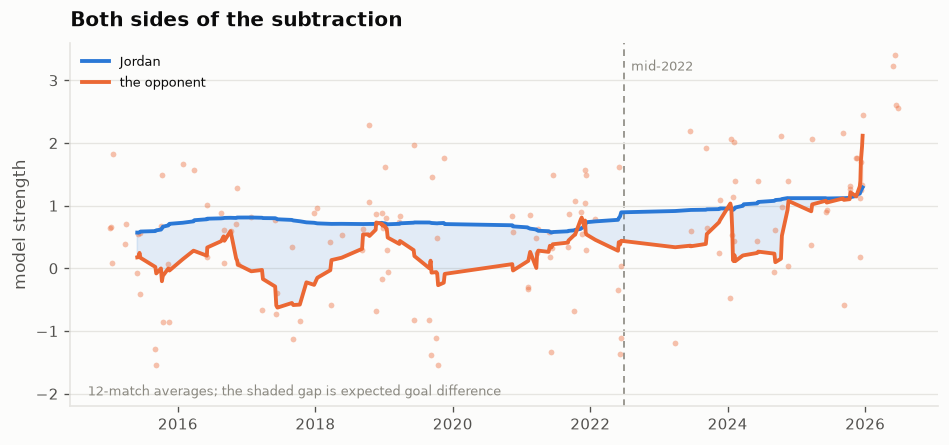

In [11]:
fig, ax = plt.subplots(figsize=(7.8, 3.6))
srt = mt.sort_values("date")
jr = srt.set_index("date").strength_at_match.rolling(12, center=True).mean()
orr = srt.set_index("date").opp_str.rolling(12, center=True).mean()
ax.fill_between(jr.index, jr.values, orr.values, where=jr.values >= orr.values,
                color=viz.BLUE, alpha=0.12, interpolate=True)
ax.fill_between(jr.index, jr.values, orr.values, where=jr.values < orr.values,
                color=viz.ORANGE, alpha=0.14, interpolate=True)
ax.scatter(srt.date, srt.opp_str, s=12, color=viz.ORANGE, alpha=0.4, linewidths=0)
ax.plot(jr.index, jr.values, color=viz.BLUE, lw=2.3, label="Jordan")
ax.plot(orr.index, orr.values, color=viz.ORANGE, lw=2.3, label="the opponent")
viz.mark_split(ax)
ax.set_ylim(-2.2, 3.6)
ax.set_ylabel("model strength")
ax.set_title("Both sides of the subtraction")
ax.annotate("12-match averages; the shaded gap is expected goal difference",
            xy=(0.02, 0.03), xycoords="axes fraction", fontsize=7.5,
            color=viz.INK_MUTED)
ax.legend(fontsize=8, loc="upper left")
viz.despine(ax)
plt.show()

**Plotted:** the same opponent strength, split by the three modes Jordan's
calendar runs in and by era. One dot per match, the heavy bar is the mode's mean,
`n` gives the matches behind each. This is what makes the orange line above saw:
every trough is a qualifying window.

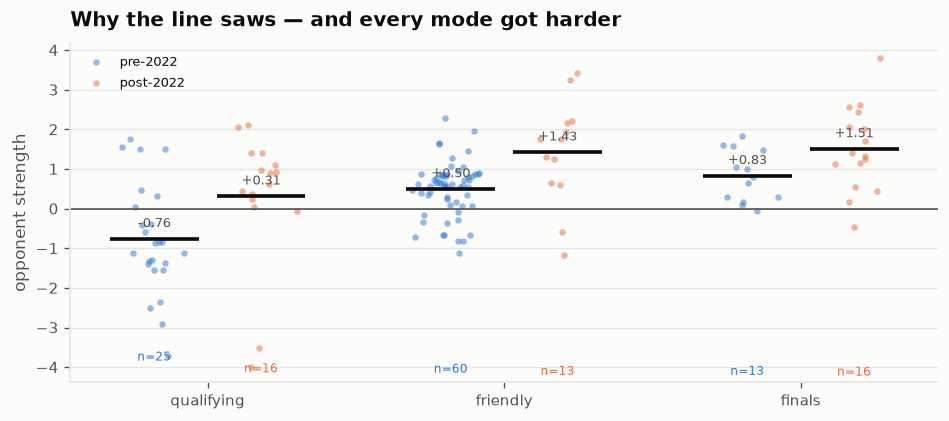

In [12]:
CATS = ["qualifying", "friendly", "finals"]
fig, ax = plt.subplots(figsize=(7.8, 3.4))
for i, c_ in enumerate(CATS):
    for off, e, col in ((-0.18, "pre", viz.BLUE), (0.18, "post", viz.ORANGE)):
        d = mt[(mt.comp_cat == c_) & (mt.era == e)]
        if not len(d):
            continue
        ax.scatter(np.full(len(d), i + off) + rng.normal(0, 0.045, len(d)),
                   d.opp_str, s=15, alpha=0.5, color=col, linewidths=0,
                   label=f"{e}-2022" if i == 0 else None)
        ax.hlines(d.opp_str.mean(), i + off - 0.15, i + off + 0.15,
                  color=viz.INK, lw=2.2, zorder=4)
        ax.annotate(f"{d.opp_str.mean():+.2f}", (i + off, d.opp_str.mean()),
                    xytext=(0, 7), ha="center", textcoords="offset points",
                    fontsize=8, color=viz.INK_2)
        ax.annotate(f"n={len(d)}", (i + off, ax.get_ylim()[0]), xytext=(0, 4),
                    ha="center", textcoords="offset points", fontsize=7,
                    color=col)
ax.axhline(0, color=viz.INK_2, lw=1.0)
ax.set_xticks(range(len(CATS)))
ax.set_xticklabels(CATS)
ax.set_ylabel("opponent strength")
ax.set_title("Why the line saws — and every mode got harder")
ax.legend(fontsize=8, loc="upper left")
viz.despine(ax)
ax.grid(axis="x", visible=False)
plt.show()

**Plotted:** friendlies only — the fixtures somebody *chose* to arrange. Line and
large markers are the yearly mean opponent strength (area = matches that year);
faint dots are individual friendlies. The four hardest are named, because the
trend is easier to believe as a fixture list than as a number.

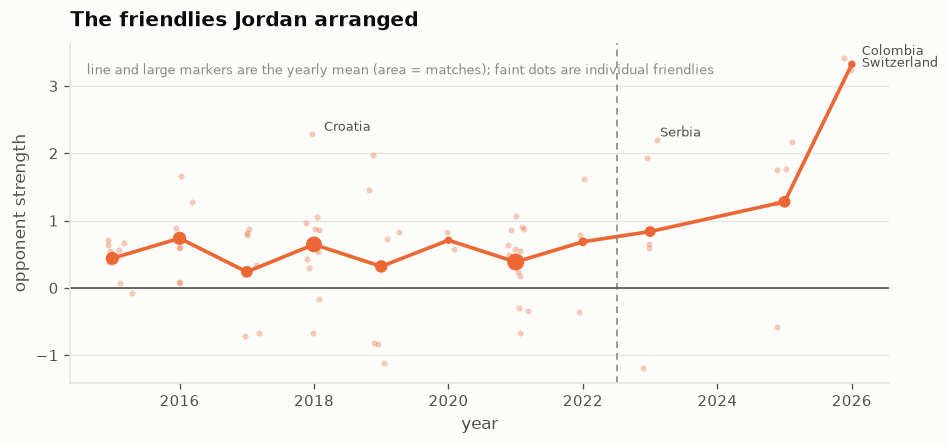

In [13]:
fig, ax = plt.subplots(figsize=(7.8, 3.6))
fr = mt[mt.comp_cat == "friendly"]
yrf = fr.groupby(fr.date.dt.year).opp_str.agg(["size", "mean"])
ax.plot(yrf.index, yrf["mean"], color=viz.ORANGE, lw=2.2, zorder=2)
ax.scatter(yrf.index, yrf["mean"], color=viz.ORANGE, s=yrf["size"] * 6, zorder=3)
ax.scatter(fr.date.dt.year + rng.normal(0, 0.10, len(fr)), fr.opp_str, s=13,
           color=viz.ORANGE, alpha=0.35, linewidths=0, zorder=1)
for _, r in fr.nlargest(4, "opp_str").iterrows():
    ax.annotate(r.opponent, (r.date.year, r.opp_str), xytext=(6, 2),
                textcoords="offset points", fontsize=7.5, color=viz.INK_2)
ax.axvline(CUT.year + 0.5, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)))
ax.axhline(0, color=viz.INK_2, lw=1.0)
ax.set_ylabel("opponent strength")
ax.set_xlabel("year")
ax.set_title("The friendlies Jordan arranged")
ax.annotate("line and large markers are the yearly mean (area = matches); "
            "faint dots are individual friendlies",
            xy=(0.02, 0.94), xycoords="axes fraction", fontsize=7.5,
            color=viz.INK_MUTED, va="top")
viz.despine(ax)
plt.show()

**The opponents got much harder — twice as fast as Jordan improved.** Backing the
opponent out of the expected goal difference, with the model's own home-advantage
term (0.27) removed:

| | pre | post | change |
|---|---|---|---|
| Jordan's strength | 0.70 | 1.11 | **+0.41** |
| the opponent's | 0.22 | 1.06 | **+0.84** |
| the gap between them | +0.48 | +0.02 | −0.45 |

The narrowing gap *understates* the hardening, because Jordan's own rise is
pushing it back open. This is not a scheduling-mix effect — holding the venue mix
fixed gives +0.25 to +0.98, and opponent strength rises inside every venue
category.

**The jaggedness is the calendar, not noise.** Qualifying groups average **−0.34**
and reach down to Pakistan at −3.99 and Cambodia at −3.73; friendlies average
+0.66; finals average **+1.20** and reach up to Argentina at +3.79. Qualifying
also carries much the widest spread (sd 1.60 against 0.90 and 0.95), because AFC
groups put minnows and real sides in the same campaign.

**And every mode hardened, chosen and drawn alike:**

| | pre | post | change |
|---|---|---|---|
| qualifying (25 → 16) | −0.76 | +0.31 | **+1.07** |
| friendly (60 → 13) | +0.50 | +1.43 | **+0.93** |
| finals (13 → 16) | +0.83 | +1.51 | **+0.68** |

Qualifying moved most, and that half is **earned** — reaching the final round of
World Cup qualifying means Pakistan and Cambodia are replaced by real teams. But
the friendlies moved almost as much, and friendlies are **arranged**: Jordan's
friendly opposition climbs from around +0.4 through the 2010s to **+1.28 in 2025
and +3.32 in 2026** (Switzerland, Colombia). Somebody decided to play better
teams, and kept deciding it.

**How much better Jordan actually got, given the opponent, is notebook 02's
question** — +0.717 [+0.203, +1.220], answerable only because the model pools the
whole 49,000-match record. Jordan's own 143 results give +0.33 [−0.43, +0.86].

### The opponent's shape: a paragraph, not a chart

🚨 **Nobody changes shape for Jordan, and Jordan changes shape for nobody** — and
that is the whole of what the formation data supports, so it gets no figure.
Teams line up in a back four about five times in six (87 of 103 covered matches),
the count of back-three opponents is **8 before 2022 and 8 after** — identical,
with the share rising only because the denominator shrank — and Jordan picks a
back three in **44%** of matches against a back three and **43%** against a back
four.

Anything beyond that is out of reach, and was worth establishing rather than
assuming. Pooling both eras for power, Jordan's result relative to expectation
differs between the two shapes by **−0.25, 95% [−1.16, +0.68]**; broken down by
full formation the cells hold six to thirty matches and the residuals bounce
between −0.60 and +1.01. An earlier era-split version *looked* like a finding:
the eight post-era back-three fixtures include **Pakistan 7–0, which alone was
78% of that bar**, and "back three" meant Hong Kong and Singapore before 2022 and
Serbia and Switzerland after.

Recovering the Arab Cup shapes was still necessary. FBref carries no Arab Cup, so
`opp_formation` was absent for ten post-era matches — and not a random ten, but
Jordan's easiest block, won most heavily. Without them the 8-versus-8 count could
not have been trusted either. Post coverage is now 41 of 45.

**The general lesson this project keeps relearning: a cell of eight matches will
always show something. Check what one result contributes before reporting a
difference between small groups.**

## Summary

| | | |
|---|---|---|
| **Supported** | Jordan abandoned the back four | 20% → 90%, **+0.70** [+0.40, +0.86] |
| | minutes concentrated on fewer men | top-11 share **+0.25** [+0.13, +0.35] |
| | the XI became more familiar | pairs rate **+0.22** [+0.12, +0.34] |
| | the opposition got much harder | opponent strength +0.22 → +1.06, in *every* mode |
| **Measured null** | players moving abroad | +0.075 [−0.12, +0.27]; every line spans zero |
| | opponents adapting to Jordan | 8 back-three opponents before, 8 after |
| | Jordan adapting to opponents | back three in 44% vs a back three, 43% vs a back four |
| **Untested** | what a European move would do | n = 1 player, eleven years |

🚨 **Two of these are one fact, and a third is a caution.** Minutes concentration
and familiarity correlate at 0.99. And the harder fixture list is not a
confounder to be adjusted away — it is *part of what improved*. A team that
arranges Switzerland and Colombia is a team that expects to compete with them.

---

**Next:** the rise was attacking, the squad narrowed, and the opposition
hardened. Notebook 04 asks the question those three set up — **who scored the
extra goals, how many players did it take, and when did they arrive?**